In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from math import ceil, log10
from collections import deque
np.set_printoptions(precision=4, suppress=True)

,subcarrier_a,subcarrier_b,abs_normalized_inner_product
0,3,3.0,1.000000e+00
1,3,4.0,6.573725e-17
2,3,5.0,4.511859e-17
3,3,7.0,3.593002e-17
4,3,3.5,6.366198e-01


,scheme,realisation,sum_Mbps,jain_index,weakest_user_Mbps,fraction_users_below_6Mbps
0,Best_subcarrier,999.5,150.372,0.223,0.000,0.704
1,Contiguous,999.5,75.110,0.737,1.971,0.345
2,Interleaved,999.5,75.336,0.772,2.534,0.326
3,Min_rate_first,999.5,92.885,0.595,6.019,0.060
4,Proportional_fair,999.5,73.074,0.556,0.131,0.427


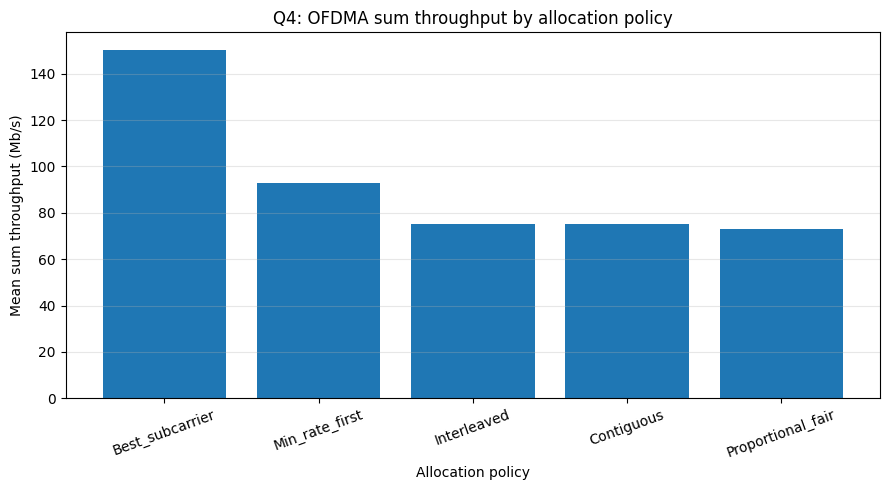

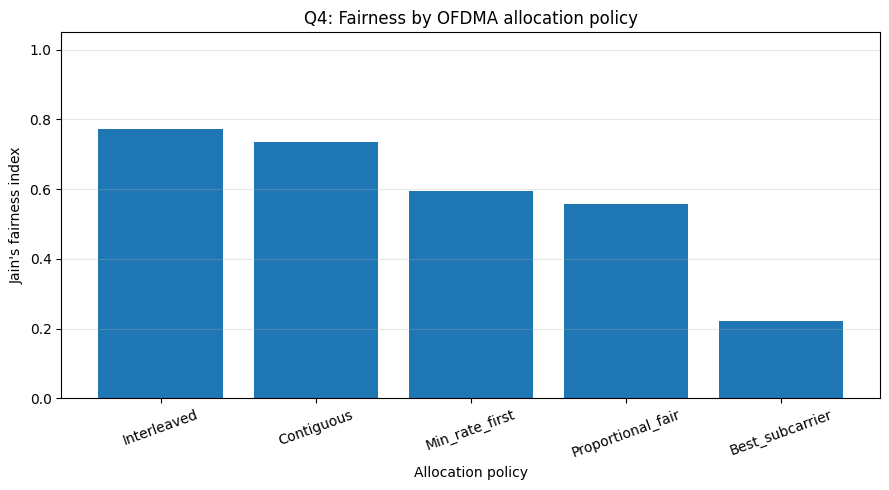

In [2]:
# Numerical orthogonality of integer-spaced subcarriers over one useful symbol.
Nfft=4096
n=np.arange(Nfft)
def tone(k): return np.exp(2j*np.pi*k*n/Nfft)
orth=[]
for a,b in [(3,3),(3,4),(3,5),(3,7),(3,3.5)]:
    orth.append([a,b,abs(np.vdot(tone(a),tone(b))/Nfft)])
q4_orth=pd.DataFrame(orth,columns=["subcarrier_a","subcarrier_b","abs_normalized_inner_product"])
display(q4_orth)
q4_orth.to_csv("q4_orthogonality.csv",index=False)

# 64-subcarrier, 8-user frequency-selective Rayleigh channel.
def jain(x):
    x=np.asarray(x)
    return (x.sum()**2)/(len(x)*np.sum(x*x)) if np.sum(x*x)>0 else 0

rng=np.random.default_rng(2026)
U,Nsc,REPS=8,64,2000
mean_snr_db=np.arange(0,24,3)
df=20e6/64
results=[]
per_user=[]
for rep in range(REPS):
    gains=np.zeros((U,Nsc))
    for u in range(U):
        taps=(rng.normal(size=8)+1j*rng.normal(size=8))/np.sqrt(2)
        taps*=np.exp(-np.arange(8)/2)
        H=np.fft.fft(taps,n=Nsc)
        gains[u]=np.abs(H)**2
    snr=10**(mean_snr_db[:,None]/10)*gains
    rates=(df*np.log2(1+snr))/1e6
    allocations={}
    allocations["Contiguous"]=np.repeat(np.arange(U),Nsc//U)
    allocations["Interleaved"]=np.arange(Nsc)%U
    allocations["Best_subcarrier"]=np.argmax(rates,axis=0)
    # Proportional fair: score relative to long-term average rate (within each realization proxy).
    avg=np.mean(rates,axis=1,keepdims=True)+1e-9
    allocations["Proportional_fair"]=np.argmax(rates/avg,axis=0)
    # Min-rate-first: allocate best remaining subcarrier to the largest deficit until Rmin.
    remaining=set(range(Nsc)); alloc=np.full(Nsc,-1); user_rate=np.zeros(U)
    while remaining and np.min(user_rate)<6:
        u=int(np.argmin(user_rate))
        k=max(remaining,key=lambda kk:rates[u,kk])
        alloc[k]=u; user_rate[u]+=rates[u,k]; remaining.remove(k)
    for k in remaining:
        alloc[k]=int(np.argmax(rates[:,k]))
    allocations["Min_rate_first"]=alloc
    for name,who in allocations.items():
        through=np.array([rates[u,who==u].sum() for u in range(U)])
        results.append([rep,name,through.sum(),jain(through),through.min(),np.mean(through<6)])
        per_user.append([rep,name,*through])
q4_results=pd.DataFrame(results,columns=["realisation","scheme","sum_Mbps","jain_index","weakest_user_Mbps","fraction_users_below_6Mbps"])
q4_summary=q4_results.groupby("scheme").mean(numeric_only=True).reset_index()
display(q4_summary.round(3))
q4_summary.to_csv("q4_allocation.csv",index=False)
pd.DataFrame(per_user,columns=["realisation","scheme"]+[f"user_{i}" for i in range(U)]).to_csv("q4_per_user.csv",index=False)

# Visualisation 1: sum throughput by allocation policy
plt.figure(figsize=(9,5))
order = q4_summary.sort_values("sum_Mbps", ascending=False)
plt.bar(order["scheme"], order["sum_Mbps"])
plt.ylabel("Mean sum throughput (Mb/s)")
plt.xlabel("Allocation policy")
plt.title("Q4: OFDMA sum throughput by allocation policy")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()

# Visualisation 2: fairness comparison
fair = q4_summary.sort_values("jain_index", ascending=False)
plt.figure(figsize=(9,5))
plt.bar(fair["scheme"], fair["jain_index"])
plt.ylim(0,1.05)
plt.ylabel("Jain's fairness index")
plt.xlabel("Allocation policy")
plt.title("Q4: Fairness by OFDMA allocation policy")
plt.xticks(rotation=20)
plt.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()
